### Image Classification

In [68]:
# fmnist dataset image classicication using CNN architecture

# import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [69]:
# check the tensorflow version
print(tf.__version__)

2.21.0


In [70]:
# Load the fmnist dataset 

fasion_mnist = tf.keras.datasets.fashion_mnist.load_data()

# Seperate the training images from the test images and labels
(train_images, train_labels), (test_images, test_labels) = fasion_mnist

In [71]:
# shape of each dataset
print(train_images.shape)
print(train_labels.shape)
print(test_images.shape)
print(test_labels.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [72]:
train_labels

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

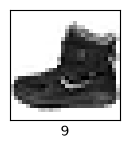

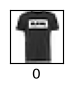

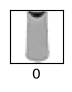

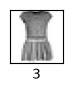

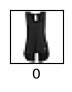

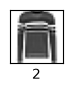

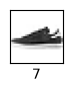

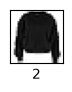

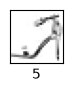

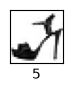

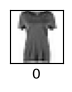

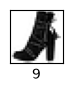

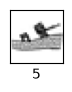

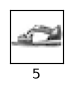

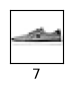

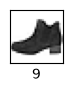

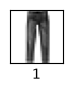

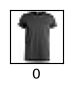

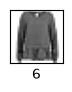

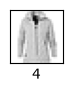

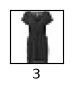

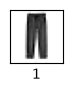

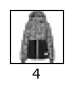

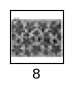

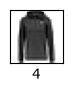

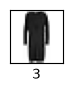

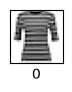

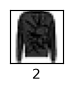

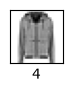

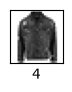

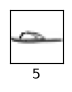

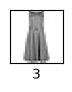

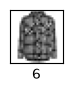

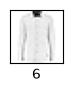

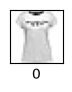

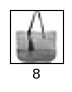

In [73]:
# Display some sample images
plt.figure(figsize=(10, 10))
for i in range (36):
    plt.subplot(6, 6, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap= plt.cm.binary)
    plt.xlabel(train_labels[i])
    plt.show()

In [74]:
len(train_images)

60000

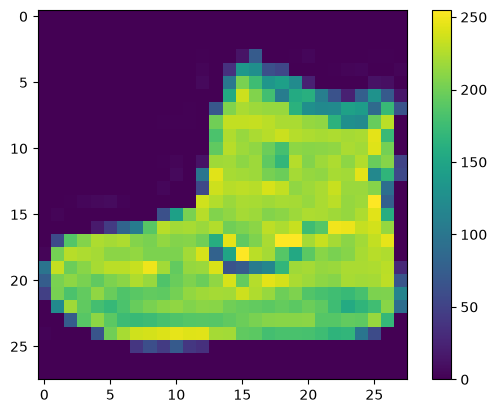

In [75]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

In [76]:
# Display the values of each picel in the image
print("pixel values:")
for row in train_images[0]:
    for pixel in row:
        print("{:3}".format(pixel), end= " ")
    print()

pixel values:
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0   0   1   4   0   0   0   0   1   1   0 
  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62  54   0   0   0   1   3   4   0   0   3 
  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134 144 123  23   0   0   0   0  12  10   0 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178 107 156 161 109  64  23  77 130  72  15 
  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216 216 163 127 121 122 146 141  88 172  66 
  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 232 233 229 223 223 21

In [77]:
# normalize the data
train_images = train_images/255
test_images = test_images/255

In [78]:
# convert images into float
train_images = train_images.astype('float32')
test_images = test_images.astype('float32')

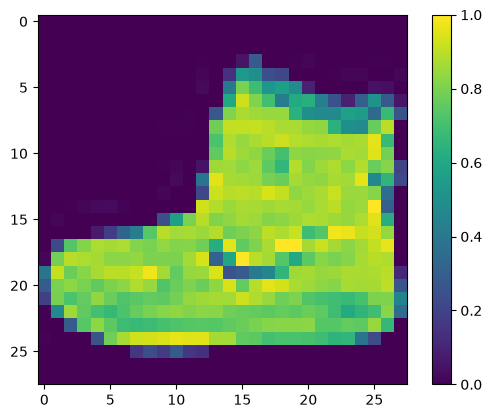

In [79]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

pixel values:
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0039 0.0 0.0 0.051 0.29 0.0 0.0 0.0039 0.016 0.0 0.0 0.0 0.0 0.0039 0.0039 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.012 0.0 0.14 0.53 0.5 0.24 0.21 0.0 0.0 0.0 0.0039 0.012 0.016 0.0 0.0 0.012 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.024 0.0 0.4 0.8 0.69 0.53 0.56 0.48 0.09 0.0 0.0 0.0 0.0 0.047 0.039 0.0 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.61 0.93 0.81 0.7 0.42 0.61 0.63 0.43 0.25 0.09 0.3 0.51 0.28 0.059 
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0039 0.0 0.27 0.81 0.87 0.85 0.85 0.85 0.64 0.5 0.47 0.48 0.57 0.55 0.35 0.67 0.26 
0.0 0.0 0

<Figure size 640x480 with 0 Axes>

<Axes: >

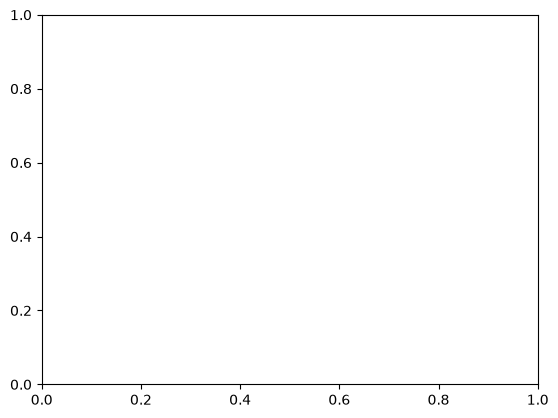

In [80]:
# Display the values of each pixel in the image
print("pixel values:")
for row in train_images[0]:
    for pixel in row:
        print("{:0.2}".format(pixel), end= " ")
    print()

# Display the complete output of the cell
display(plt.gcf())
display(plt.gca())

In [81]:
# Reshape the dimensions
train_images = train_images.reshape(train_images.shape[0], 28, 28, 1)
test_images= test_images.reshape(test_images.shape[0], 28, 28, 1)

In [82]:
# Build the model

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),    #input layer
    tf.keras.layers.Conv2D(32, (3,3), activation= 'relu'),   #convolutional layer
    tf.keras.layers.MaxPool2D(pool_size=(3, 3)),   #pooling layer
    tf.keras.layers.Conv2D(filters = 64, kernel_size= (3,3)),   #convolutional layer
    tf.keras.layers.MaxPooling2D(),   #pooling layer
    tf.keras.layers.Flatten(),   #flatten layer
    tf.keras.layers.Dense(10, activation= 'softmax')   #output layer
])

# compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 6, 6, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         5,770 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,586 (96.04 KB)

 Trainable params: 24,586 (96.04 KB)

 Non-trainable params: 0 (0.00 B)

In [83]:
# train the mdoel
model.fit(train_images, train_labels, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8057 - loss: 0.5454 - val_accuracy: 0.8530 - val_loss: 0.4054
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8741 - loss: 0.3539 - val_accuracy: 0.8786 - val_loss: 0.3431
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8874 - loss: 0.3123 - val_accuracy: 0.8902 - val_loss: 0.3092
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8964 - loss: 0.2860 - val_accuracy: 0.8929 - val_loss: 0.3012
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.9026 - loss: 0.2667 - val_accuracy: 0.8935 - val_loss: 0.2936
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9084 - loss: 0.2513 - val_accuracy: 0.8988 - val_loss: 0.2879
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.9127 - loss: 0.2366 - val_accuracy: 0.8978 - val_loss: 0.2921
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9191 - loss: 0.2

In [84]:
# model evaluation
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print('\nTest loss:', test_loss)
print('\nTest accuracy:', test_acc)

313/313 - 1s - 3ms/step - accuracy: 0.8975 - loss: 0.3067

Test loss: 0.3067370653152466

Test accuracy: 0.8974999785423279


In [85]:
# save the model
model.save('models_saved/fashion_mnist_model.h5')

### Make predictions

In [86]:
test_images.shape

(10000, 28, 28, 1)

In [87]:
predictions = model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [88]:
predictions[0]

array([2.3604660e-09, 3.8033094e-13, 9.8117434e-09, 4.2234863e-10,
       6.9942638e-09, 3.7140664e-04, 3.9950695e-08, 4.0268328e-04,
       1.9356976e-06, 9.9922383e-01], dtype=float32)

In [89]:
np.argmax(predictions[50])

np.int64(4)